In [ ]:
import os

# Si el repo ya está clonado (por ejemplo, al volver a hacer Run all), no se vuelve a clonar
if not os.path.isdir("/content/repo"):
    !git clone https://github.com/ana-castillo-zuain/procesamiento-de-imagenes.git /content/repo
%cd /content/repo

Cloning into '/content/repo'...
remote: Enumerating objects: 2367, done.
remote: Total 2367 (delta 0), reused 0 (delta 0), pack-reused 2367 (from 2)
Receiving objects: 100% (2367/2367), 150.38 MiB | 18.97 MiB/s, done.
Resolving deltas: 100% (51/51), done.
Updating files: 100% (9938/9938), done.
/content/repo


In [ ]:
import gc
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# La GPU pide memoria a medida que la necesita (evita errores de memoria al correr varios experimentos seguidos).
# Tiene que ejecutarse antes de cualquier otra operación de TensorFlow.
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

from tensorflow import keras
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input, Lambda, GlobalAveragePooling2D
from dataclasses import dataclass

SEED_VALUE = 41
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

# --- Rutas (relativas a la raíz del repo: en Colab, hacer antes %cd /content/repo)
RAIZ = Path(".")
DIR_IMG = RAIZ / "data" / "raw" / "images"
DIR_LAB = RAIZ / "data" / "raw" / "labels"
DIR_SPLITS = RAIZ / "data" / "splits"

FOLDS = ["solarpanels_val", "geo_kingston_val", "PV01_val"]

if not DIR_IMG.is_dir() or not DIR_LAB.is_dir() or not DIR_SPLITS.is_dir():
    raise FileNotFoundError("No encontré data/raw y data/splits en %s. Pasate a la raíz del repo "
                            "(por ejemplo, %%cd /content/repo) y volvé a correr." % Path.cwd())


def grupo_de(nombre: str) -> str:
    """Los nombres de archivo delatan de qué fuente viene cada imagen."""
    if nombre.startswith("PV01"):           return "PV01"
    if nombre.startswith("solarpanels_hd"): return "solarpanels_hd"
    if nombre.startswith("kingston2"):      return "kingston2"
    if nombre.startswith("kingston_"):      return "kingston"
    return "geo_unknown"


def leer_yolo(ruta):
    """Lee un .txt en formato YOLO -> lista de (clase, cx, cy, w, h) normalizados."""
    cajas = []
    for linea in Path(ruta).read_text().splitlines():
        if not linea.strip():
            continue
        partes = linea.split()
        cajas.append((int(float(partes[0])), *map(float, partes[1:5])))
    return cajas


# Clases 1 y 2 no son paneles. Si un .txt sólo tiene esas filas, la imagen es negativa.
CLASES_NEGATIVAS = {1, 2}


def es_panel(cls):
    return cls not in CLASES_NEGATIVAS


# Todas las imágenes y su label calculado desde los labels crudos (para la validación 6)
TODAS = sorted(p.stem for p in DIR_IMG.glob("*.png"))
LABEL_RAW = {n: int(any(es_panel(c[0]) for c in leer_yolo(DIR_LAB / (n + ".txt")))) for n in TODAS}
print("data/raw: %d imágenes | %d positivas | %d negativas"
      % (len(TODAS), sum(LABEL_RAW.values()), len(TODAS) - sum(LABEL_RAW.values())))


def leer_lista(ruta):
    """Líneas no vacías de un train.txt / val.txt (rutas relativas a la raíz del repo)."""
    return [l.strip() for l in Path(ruta).read_text().splitlines() if l.strip()]


def tiene_cajas(ruta):
    """1 si el .txt limpio tiene al menos una línea no vacía, 0 si está vacío."""
    return int(any(l.strip() for l in Path(ruta).read_text().splitlines()))


def armar_fold(fold):
    """Una fila por imagen del fold: ruta, nombre, fuente, split y ruta de su etiqueta limpia."""
    dir_fold = DIR_SPLITS / fold
    filas = []
    for sp in ("train", "val"):
        for ruta in leer_lista(dir_fold / (sp + ".txt")):
            nombre = Path(ruta).stem
            filas.append(dict(ruta_imagen=ruta, nombre=nombre, fuente=grupo_de(nombre), split=sp,
                              ruta_label=(dir_fold / "labels" / sp / (nombre + ".txt")).as_posix()))
    return pd.DataFrame(filas, columns=["ruta_imagen", "nombre", "fuente", "split", "ruta_label"])


def validar_estructura(fold, df):
    """Validaciones 1 a 5: repetidas, fuentes cruzadas, archivos faltantes, huérfanos y cobertura."""
    errores = []
    tr, va = df[df.split == "train"], df[df.split == "val"]

    for sp, sub in (("train", tr), ("val", va)):
        if sub.empty:
            errores.append("%s está vacío" % sp)
        rep = sorted(set(sub.nombre[sub.nombre.duplicated()]))
        if rep:
            errores.append("%s tiene %d imágenes repetidas: %s" % (sp, len(rep), rep[:5]))
    cruzadas = sorted(set(tr.nombre) & set(va.nombre))
    if cruzadas:
        errores.append("%d imágenes en train y val a la vez: %s" % (len(cruzadas), cruzadas[:5]))

    fuentes = sorted(set(tr.fuente) & set(va.fuente))
    if fuentes:
        errores.append("fuentes en train y val a la vez: %s" % fuentes)

    sin_imagen = [r for r in df.ruta_imagen if not Path(r).is_file()]
    if sin_imagen:
        errores.append("%d imágenes listadas no existen: %s" % (len(sin_imagen), sin_imagen[:5]))
    sin_label = [r for r in df.ruta_label if not Path(r).is_file()]
    if sin_label:
        errores.append("%d imágenes sin etiqueta: %s" % (len(sin_label), sin_label[:5]))

    for sp, sub in (("train", tr), ("val", va)):
        en_disco = {p.stem for p in (DIR_SPLITS / fold / "labels" / sp).glob("*.txt")}
        huerfanas = sorted(en_disco - set(sub.nombre))
        if huerfanas:
            errores.append("labels/%s tiene %d etiquetas huérfanas: %s" % (sp, len(huerfanas), huerfanas[:5]))

    afuera = sorted(set(TODAS) - set(df.nombre))
    if afuera:
        errores.append("%d imágenes de data/raw no están en ningún split: %s" % (len(afuera), afuera[:5]))
    ajenas = sorted(set(df.nombre) - set(TODAS))
    if ajenas:
        errores.append("%d imágenes listadas no están en data/raw/images: %s" % (len(ajenas), ajenas[:5]))

    if errores:
        raise ValueError("[%s] validación fallida:\n  - %s" % (fold, "\n  - ".join(errores)))


def validar_contra_raw(fold, df):
    """Validación 6: el label de data/splits tiene que coincidir con el calculado desde data/raw/labels."""
    raw = df.nombre.map(LABEL_RAW)
    dif = df[df.label != raw]
    if len(dif):
        tabla = pd.DataFrame(dict(fold=fold, nombre=dif.nombre, split=dif.split,
                                  label_splits=dif.label, label_raw=raw[dif.index]))
        print(tabla.to_string(index=False))
        raise ValueError("[%s] %d imágenes con label distinto entre data/splits y data/raw/labels"
                         % (fold, len(dif)))


# Primero se arman y validan los tres folds. Recién después (sección 5) se escribe algo en disco.
DFS = {}
for fold in FOLDS:
    df = armar_fold(fold)
    validar_estructura(fold, df)
    df["label"] = [tiene_cajas(r) for r in df.ruta_label]
    validar_contra_raw(fold, df)
    DFS[fold] = df
    print("%-17s OK  (train %d, val %d)"
          % (fold, (df.split == "train").sum(), (df.split == "val").sum()))

data/raw: 900 imágenes | 805 positivas | 95 negativas
solarpanels_val   OK  (train 584, val 316)
geo_kingston_val  OK  (train 794, val 106)
PV01_val          OK  (train 422, val 478)


In [ ]:
from concurrent.futures import ThreadPoolExecutor


def cargar_rgb(ruta):
    """Imagen como RGB uint8 (algunas PNG están en modo paleta)."""
    with Image.open(ruta) as im:
        return np.array(im.convert("RGB"))


# Cada imagen se lee una sola vez (en paralelo) y después cada fold toma las suyas
rutas = sorted({r for df in DFS.values() for r in df.ruta_imagen})
with ThreadPoolExecutor() as ex:
    IMG = dict(zip(rutas, ex.map(cargar_rgb, rutas)))
print("%d imágenes en memoria" % len(IMG))


def xy(fold, split):
    sub = DFS[fold][DFS[fold].split == split]
    X = np.stack([IMG[r] for r in sub.ruta_imagen])        # uint8 0-255, (N, 256, 256, 3)
    y = sub.label.to_numpy().astype("float32")              # 1 = con paneles, 0 = sin paneles
    return X, y


X_train_1, y_train_1 = xy("solarpanels_val", "train")
X_val_1,   y_val_1   = xy("solarpanels_val", "val")
X_train_2, y_train_2 = xy("geo_kingston_val", "train")
X_val_2,   y_val_2   = xy("geo_kingston_val", "val")
X_train_3, y_train_3 = xy("PV01_val", "train")
X_val_3,   y_val_3   = xy("PV01_val", "val")

for i, (Xt, yt, Xv, yv) in enumerate([(X_train_1, y_train_1, X_val_1, y_val_1),
                                      (X_train_2, y_train_2, X_val_2, y_val_2),
                                      (X_train_3, y_train_3, X_val_3, y_val_3)], start=1):
    print(f"Fold {i}: train {Xt.shape} pos {int(yt.sum())} neg {int(len(yt) - yt.sum())} | "
          f"val {Xv.shape} pos {int(yv.sum())} neg {int(len(yv) - yv.sum())}")

900 imágenes en memoria
Fold 1: train (584, 256, 256, 3) pos 521 neg 63 | val (316, 256, 256, 3) pos 284 neg 32
Fold 2: train (794, 256, 256, 3) pos 761 neg 33 | val (106, 256, 256, 3) pos 44 neg 62
Fold 3: train (422, 256, 256, 3) pos 328 neg 94 | val (478, 256, 256, 3) pos 477 neg 1


# Redes pre-entrenadas

Todas las redes se entrenan con las mismas funciones genéricas. A `entrenar_folds` se le pasa el nombre de la red
(una de las claves de `REDES`) y la configuración del experimento:

- `fine_tune`: `0` deja todo el extractor congelado; `"ultimo_bloque"` descongela el último bloque de esa red
  (`block5` en VGG, `conv5` en ResNet50, el último stage en ConvNeXt, `block7` en EfficientNet); un número `N`
  descongela las últimas `N` capas.
- `lr` y `epocas`: el learning rate inicial baja con *cosine decay* hasta casi 0 en la última época.
- `augmentar`: agrega data augmentation (solo actúa durante el entrenamiento).

`entrenar_folds_secuencial` hace el fine-tuning por fases: primero solo la cabeza y después va descongelando
bloques desde el más cercano a la cabeza hacia abajo.

Las capas de BatchNorm quedan siempre congeladas, como recomienda la guía de transfer learning de Keras.

In [ ]:
@dataclass(frozen=True)
class DatasetConfig:
    IMG_HEIGHT: int = 256   # tamaño original de las imágenes satelitales
    IMG_WIDTH:  int = 256
    CHANNELS:   int = 3


@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE:  int   = 32
    DENSE_UNITS: int   = 128   # neuronas de la capa densa oculta de la cabeza
    DROPOUT:     float = 0.6
    UMBRAL:      float = 0.5   # probabilidad a partir de la cual se predice "con paneles"


# Los 3 folds que ya están en memoria (imágenes uint8 0-255, labels 0/1)
FOLDS_CV = {
    1: ("solarpanels_val",  X_train_1, y_train_1, X_val_1, y_val_1),
    2: ("geo_kingston_val", X_train_2, y_train_2, X_val_2, y_val_2),
    3: ("PV01_val",         X_train_3, y_train_3, X_val_3, y_val_3),
}

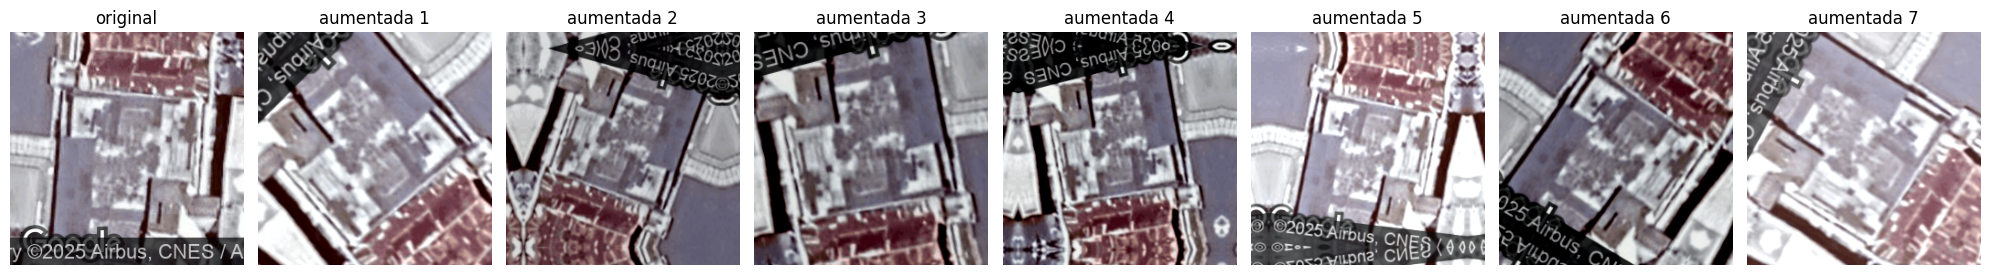

In [ ]:
# =========================================================
# Data augmentation (solo actúa en fit; en evaluate y predict no hace nada)
# =========================================================
def capas_aumentacion():
    return Sequential([
        tf.keras.layers.RandomFlip("horizontal_and_vertical"),          # en satelitales no hay "arriba"
        tf.keras.layers.RandomRotation(0.25, fill_mode="reflect"),      # hasta ±90°
        tf.keras.layers.RandomZoom(0.2, fill_mode="reflect"),           # cambios de escala entre fuentes
        tf.keras.layers.RandomBrightness(0.2, value_range=(0, 255)),    # cambios de brillo entre fuentes
        tf.keras.layers.RandomContrast(0.2),
    ], name="aumentacion")


# Control visual: una imagen original y 7 versiones aumentadas
def mostrar_aumentos(X, idx=0, n=8):
    aug = capas_aumentacion()
    plt.figure(figsize=(2.5 * n, 2.8))
    for k in range(n):
        img = X[idx] if k == 0 else aug(X[idx:idx + 1].astype("float32"), training=True)[0]
        img = np.clip(np.asarray(img), 0, 255).astype("uint8")
        plt.subplot(1, n, k + 1)
        plt.imshow(img)
        plt.title("original" if k == 0 else f"aumentada {k}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


mostrar_aumentos(X_train_1, idx=0)

## Funciones genéricas

In [ ]:
# =========================================================
# Redes disponibles: clase de Keras, preprocesamiento y nombre del último bloque
# =========================================================
REDES = {
    "VGG16":    dict(clase=tf.keras.applications.VGG16,
                     preprocesar=tf.keras.applications.vgg16.preprocess_input,
                     ultimo_bloque="block5"),
    "VGG19":    dict(clase=tf.keras.applications.VGG19,
                     preprocesar=tf.keras.applications.vgg19.preprocess_input,
                     ultimo_bloque="block5"),
    "ResNet50": dict(clase=tf.keras.applications.ResNet50,
                     preprocesar=tf.keras.applications.resnet50.preprocess_input,
                     ultimo_bloque="conv5"),
    # ConvNeXt y EfficientNet traen su normalización adentro (esperan 0-255): no se preprocesa afuera
    "ConvNeXtTiny":   dict(clase=tf.keras.applications.ConvNeXtTiny,
                           preprocesar=None,
                           ultimo_bloque="convnext_tiny_downsampling_block_2"),
}


def configurar_entrenables(base, red, fine_tune):
    """Congela el extractor y descongela lo que indique fine_tune. Devuelve cuántas capas quedan entrenables.

    fine_tune = 0               -> todo congelado
    fine_tune = N (entero)      -> las últimas N capas
    fine_tune = "ultimo_bloque" -> el último bloque de esa red (REDES[red]["ultimo_bloque"])
    fine_tune = "prefijo"       -> desde la primera capa cuyo nombre empieza con ese prefijo
    """
    capas = base.layers
    if isinstance(fine_tune, str):
        prefijo = REDES[red]["ultimo_bloque"] if fine_tune == "ultimo_bloque" else fine_tune
        desde = next((i for i, capa in enumerate(capas) if capa.name.startswith(prefijo)), None)
        if desde is None:
            raise ValueError(f"{red} no tiene capas que empiecen con '{prefijo}'")
    else:
        desde = len(capas) - int(fine_tune)

    base.trainable = True
    for i, capa in enumerate(capas):
        capa.trainable = i >= desde
        # BatchNorm siempre congelada: con batches chicos, actualizar sus estadísticas arruina las features
        if isinstance(capa, tf.keras.layers.BatchNormalization):
            capa.trainable = False
    return sum(capa.trainable for capa in capas)


# =========================================================
# Modelo: red pre-entrenada (sin su cabeza) + clasificador propio
# =========================================================
def construir_modelo(red, fine_tune=0, lr=1e-5, epocas=20, n_train=None, augmentar=False):
    cfg = REDES[red]
    input_shape = (DatasetConfig.IMG_HEIGHT, DatasetConfig.IMG_WIDTH, DatasetConfig.CHANNELS)
    base = cfg["clase"](input_shape=input_shape, include_top=False, weights="imagenet")
    configurar_entrenables(base, red, fine_tune)

    entrada = Input(shape=input_shape)
    x = entrada
    if augmentar:
        x = capas_aumentacion()(x)                                   # antes del preprocesamiento (0-255)
    if cfg["preprocesar"] is not None:
        x = Lambda(cfg["preprocesar"], name="preprocesamiento")(x)  # preprocesamiento oficial de la red
    x = base(x, training=False)                                      # extractor siempre en modo inferencia
    x = GlobalAveragePooling2D()(x)
    x = Dense(TrainingConfig.DENSE_UNITS, activation="relu")(x)
    x = Dropout(TrainingConfig.DROPOUT)(x)
    salida = Dense(1, activation="sigmoid")(x)                       # probabilidad de "con paneles"
    model = Model(entrada, salida, name=red)

    # El learning rate baja hasta casi 0 al final: el resultado no depende de en qué época se cortó
    pasos = int(np.ceil(n_train / TrainingConfig.BATCH_SIZE)) * epocas
    schedule = tf.keras.optimizers.schedules.CosineDecay(initial_learning_rate=lr, decay_steps=pasos)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=schedule),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model

In [ ]:
# =========================================================
# Entrenamiento y evaluación en los 3 folds
# =========================================================
RESULTADOS = {}   # nombre del experimento -> DataFrame con sus métricas (para la comparación final)
PROBS = {}        # nombre del experimento -> {fold: (y, prob)}

def entrenar_folds(red, fine_tune=0, lr=1e-5, epocas=20, augmentar=False, nombre=None, verbose=2):
    if nombre is None:
        nombre = f"{red} ft={fine_tune}" + (" + aug" if augmentar else "")
    resultados, historiales = [], {}
    for i, (fold, X_tr, y_tr, X_va, y_va) in FOLDS_CV.items():
        print(f"\n===== {nombre} | lr {lr:g} | {epocas} épocas | Fold {i} ({fold}) =====")
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED_VALUE)   # mismo punto de partida en cada fold

        # Pesos por clase: hay muchas más imágenes con paneles que sin paneles
        n, n_pos = len(y_tr), int(y_tr.sum())
        pesos = {0: n / (2 * (n - n_pos)), 1: n / (2 * n_pos)}

        model = construir_modelo(red, fine_tune, lr=lr, epocas=epocas, n_train=n, augmentar=augmentar)
        if i == 1:
            model.summary()

        history = model.fit(
            X_tr, y_tr,
            validation_data=(X_va, y_va),
            epochs=epocas,
            batch_size=TrainingConfig.BATCH_SIZE,
            class_weight=pesos,
            shuffle=True,
            verbose=verbose,
        )
        historiales[i] = history.history

        ev = model.evaluate(X_va, y_va, batch_size=TrainingConfig.BATCH_SIZE, return_dict=True, verbose=0)
        prob = model.predict(X_va, batch_size=TrainingConfig.BATCH_SIZE, verbose=0).ravel()
        pred = (prob >= TrainingConfig.UMBRAL).astype(int)
        y = y_va.astype(int)
        tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
        fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
        recall_pos = tp / (tp + fn) if tp + fn else np.nan
        recall_neg = tn / (tn + fp) if tn + fp else np.nan
        PROBS.setdefault(nombre, {})[i] = (y, prob)
        resultados.append(dict(
            modelo=nombre, red=red, fine_tune=str(fine_tune), lr=lr, epocas=epocas, augmentar=augmentar,
            fold=f"{i} ({fold})",
            loss=ev["loss"], accuracy=ev["accuracy"], auc=ev["auc"],
            accuracy_balanceada=np.nanmean([recall_pos, recall_neg]),
            recall_pos=recall_pos, recall_neg=recall_neg,
            tn=tn, fp=fp, fn=fn, tp=tp,
        ))
        print(f"Fold {i}: acc {ev['accuracy']:.3f} | AUC {ev['auc']:.3f} | "
              f"recall pos {recall_pos:.3f} | recall neg {recall_neg:.3f} | TN {tn} FP {fp} FN {fn} TP {tp}")

        del model
        gc.collect()

    res = pd.DataFrame(resultados)
    RESULTADOS[nombre] = res
    return res, historiales


# =========================================================
# Gráficos de loss y accuracy por fold
# =========================================================
def graficar(historiales, titulo):
    fig, axes = plt.subplots(2, len(historiales), figsize=(5 * len(historiales), 7), squeeze=False)
    for j, (i, h) in enumerate(historiales.items()):
        for k, metrica in enumerate(["loss", "accuracy"]):
            ax = axes[k, j]
            ax.plot(h[metrica], "g", label="Train")
            ax.plot(h["val_" + metrica], "b", label="Validation")
            ax.set_title(f"Fold {i} ({FOLDS_CV[i][0]}) - {metrica}")
            ax.set_xlabel("Epoch")
            ax.grid(True)
            ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


# =========================================================
# Resumen de un experimento
# =========================================================
COLS = ["modelo", "fold", "loss", "accuracy", "auc", "accuracy_balanceada",
        "recall_pos", "recall_neg", "tn", "fp", "fn", "tp"]


def resumir(res):
    """Tabla por fold. Las métricas de negativas se promedian solo en los folds 1 y 2:
    en el fold 3 la validación tiene una sola imagen sin paneles."""
    print(res[COLS].to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    f12 = res[res.fold.str[0].isin(["1", "2"])]
    print("\nPromedio folds 1 y 2:")
    print(f12[["auc", "accuracy_balanceada", "recall_pos", "recall_neg"]].mean().round(3).to_string())
    print("Recall positivas fold 3: %.3f" % res.loc[res.fold.str[0] == "3", "recall_pos"].iloc[0])

In [ ]:
# =========================================================
# Fine-tuning secuencial (gradual unfreezing)
# Fase 0: solo la cabeza. Fase 1: + el último bloque. Fase 2: + el anteúltimo. Y así.
# =========================================================
# Bloques de cada red, del más cercano a la cabeza al más lejano
BLOQUES = {
    "VGG16":          ["block5", "block4", "block3"],
    "VGG19":          ["block5", "block4", "block3"],
    "ResNet50":       ["conv5", "conv4", "conv3"],
    "ConvNeXtTiny":   ["convnext_tiny_downsampling_block_2", "convnext_tiny_downsampling_block_1",
                       "convnext_tiny_downsampling_block_0"],
    "EfficientNetB0": ["block7", "block6", "block5"],
}


def extractor_de(model):
    """La red pre-entrenada dentro del modelo (la submodelo que no es la aumentación)."""
    return next(capa for capa in model.layers if hasattr(capa, "layers") and capa.name != "aumentacion")


def compilar(model, lr, epocas, n_train):
    pasos = int(np.ceil(n_train / TrainingConfig.BATCH_SIZE)) * epocas
    schedule = tf.keras.optimizers.schedules.CosineDecay(initial_learning_rate=lr, decay_steps=pasos)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=schedule),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )


def entrenar_folds_secuencial(red, fases, augmentar=False, nombre=None, verbose=2):
    """fases: lista de dicts con
         bloques = cuántos bloques descongelar (0 = solo la cabeza, 1 = + último bloque, 2 = + anteúltimo...)
         epocas  = épocas de esa fase
         lr      = learning rate inicial de esa fase (baja con cosine decay dentro de la fase)
    """
    if nombre is None:
        nombre = f"{red} secuencial {len(fases)} fases" + (" + aug" if augmentar else "")
    resultados, historiales = [], {}
    for i, (fold, X_tr, y_tr, X_va, y_va) in FOLDS_CV.items():
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED_VALUE)   # mismo punto de partida en cada fold

        n, n_pos = len(y_tr), int(y_tr.sum())
        pesos = {0: n / (2 * (n - n_pos)), 1: n / (2 * n_pos)}

        model = construir_modelo(red, fine_tune=0, lr=fases[0]["lr"], epocas=fases[0]["epocas"],
                                 n_train=n, augmentar=augmentar)
        base = extractor_de(model)

        hist = {}
        cortes = []          # época en la que empieza cada fase (para el gráfico)
        epoca = 0
        for k, fase in enumerate(fases):
            b = fase["bloques"]
            if b > len(BLOQUES[red]):
                raise ValueError(f"{red} tiene definidos {len(BLOQUES[red])} bloques en BLOQUES")
            # Descongela desde el bloque más profundo de esta fase hasta el final (BatchNorm siempre congelada)
            capas_entrenables = configurar_entrenables(base, red, 0 if b == 0 else BLOQUES[red][b - 1])
            compilar(model, fase["lr"], fase["epocas"], n)   # recompilar: si no, el cambio de trainable no se aplica
            print(f"\n===== {nombre} | Fold {i} ({fold}) | fase {k}: "
                  f"{'solo cabeza' if b == 0 else 'cabeza + ' + ', '.join(BLOQUES[red][:b])} | "
                  f"{capas_entrenables} capas del extractor entrenables | lr {fase['lr']:g} | {fase['epocas']} épocas =====")

            cortes.append(epoca)
            h = model.fit(
                X_tr, y_tr,
                validation_data=(X_va, y_va),
                initial_epoch=epoca, epochs=epoca + fase["epocas"],
                batch_size=TrainingConfig.BATCH_SIZE,
                class_weight=pesos,
                shuffle=True,
                verbose=verbose,
            )
            for clave, valores in h.history.items():
                hist.setdefault(clave, []).extend(valores)
            epoca += fase["epocas"]

        hist["_cortes"] = cortes
        historiales[i] = hist

        ev = model.evaluate(X_va, y_va, batch_size=TrainingConfig.BATCH_SIZE, return_dict=True, verbose=0)
        prob = model.predict(X_va, batch_size=TrainingConfig.BATCH_SIZE, verbose=0).ravel()
        pred = (prob >= TrainingConfig.UMBRAL).astype(int)
        y = y_va.astype(int)
        tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
        fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
        recall_pos = tp / (tp + fn) if tp + fn else np.nan
        recall_neg = tn / (tn + fp) if tn + fp else np.nan
        PROBS.setdefault(nombre, {})[i] = (y, prob)
        resultados.append(dict(
            modelo=nombre, red=red, fine_tune="secuencial", lr=fases[-1]["lr"], epocas=epoca,
            augmentar=augmentar, fold=f"{i} ({fold})",
            loss=ev["loss"], accuracy=ev["accuracy"], auc=ev["auc"],
            accuracy_balanceada=np.nanmean([recall_pos, recall_neg]),
            recall_pos=recall_pos, recall_neg=recall_neg,
            tn=tn, fp=fp, fn=fn, tp=tp,
        ))
        print(f"Fold {i}: acc {ev['accuracy']:.3f} | AUC {ev['auc']:.3f} | "
              f"recall pos {recall_pos:.3f} | recall neg {recall_neg:.3f} | TN {tn} FP {fp} FN {fn} TP {tp}")

        del model
        gc.collect()

    res = pd.DataFrame(resultados)
    RESULTADOS[nombre] = res
    return res, historiales


# =========================================================
# Gráficos del fine-tuning secuencial: marca con líneas punteadas dónde empieza cada fase
# =========================================================
def graficar_fases(historiales, titulo):
    fig, axes = plt.subplots(2, len(historiales), figsize=(5 * len(historiales), 7), squeeze=False)
    for j, (i, h) in enumerate(historiales.items()):
        for k, metrica in enumerate(["loss", "accuracy"]):
            ax = axes[k, j]
            ax.plot(h[metrica], "g", label="Train")
            ax.plot(h["val_" + metrica], "b", label="Validation")
            for corte in h.get("_cortes", [])[1:]:
                ax.axvline(corte - 0.5, color="gray", linestyle="--", linewidth=1)
            ax.set_title(f"Fold {i} ({FOLDS_CV[i][0]}) - {metrica}")
            ax.set_xlabel("Epoch")
            ax.grid(True)
            ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

## Umbral y métricas

Las predicciones de validación de los 3 folds cubren las 900 imágenes una sola vez, y cada una viene de un modelo que
no la vio al entrenar. Con esas predicciones juntas se elige, para cada modelo, el umbral que maximiza la
*balanced accuracy*. Como el umbral se elige con las mismas predicciones con las que después se mide, las métricas con
ese umbral quedan algo optimistas.

Precision, recall y F1 son de la clase positiva ("con paneles").

In [ ]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)

METRICAS = ["precision", "recall", "f1", "auc", "accuracy", "balanced_accuracy"]


def _metricas(y, p, umbral):
    y = np.asarray(y).astype(int)
    p = np.asarray(p)
    pred = (p >= umbral).astype(int)
    tn = int(((pred == 0) & (y == 0)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tp = int(((pred == 1) & (y == 1)).sum())
    ambas_clases = 0 < y.sum() < len(y)
    return dict(
        # precision, recall y f1 de la clase positiva ("con paneles")
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        f1=f1_score(y, pred, zero_division=0),
        auc=roc_auc_score(y, p) if ambas_clases else np.nan,                       # no depende del umbral
        accuracy=accuracy_score(y, pred),
        balanced_accuracy=balanced_accuracy_score(y, pred) if ambas_clases else np.nan,
        tn=tn, fp=fp, fn=fn, tp=tp,
    )


def predicciones_juntas(nombre):
    """y y probabilidades de validación de los 3 folds juntas (900 imágenes, cada una una sola vez)."""
    y = np.concatenate([y for y, _ in PROBS[nombre].values()])
    p = np.concatenate([p for _, p in PROBS[nombre].values()])
    return y, p


def metricas_umbral(nombre, umbral=0.5, mostrar=True):
    """Métricas de un experimento ya corrido, recalculadas con otro umbral (sin reentrenar)."""
    filas = [dict(fold=f"{i} ({FOLDS_CV[i][0]})", **_metricas(y, p, umbral))
             for i, (y, p) in PROBS[nombre].items()]
    filas.append(dict(fold="todos juntos", **_metricas(*predicciones_juntas(nombre), umbral)))
    tabla = pd.DataFrame(filas)
    if mostrar:
        print(f"{nombre} | umbral {umbral:.2f}\n")
        print(tabla.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
        f12 = tabla[tabla.fold.str[0].isin(["1", "2"])]
        print("\nPromedio folds 1 y 2:")
        print(f12[METRICAS].mean().round(3).to_string())
    return tabla


def barrer_umbral(nombre, umbrales=np.round(np.arange(0.05, 0.96, 0.01), 2), mostrar=False):
    """Balanced accuracy, F1 y recall de cada clase para cada umbral, con las predicciones de los 3 folds juntas."""
    y, p = predicciones_juntas(nombre)
    filas = []
    for u in umbrales:
        m = _metricas(y, p, u)
        filas.append(dict(umbral=u, recall_pos=m["recall"], recall_neg=m["tn"] / (m["tn"] + m["fp"]),
                          balanced_accuracy=m["balanced_accuracy"], f1=m["f1"]))
    tabla = pd.DataFrame(filas)
    if mostrar:
        print(tabla.round(3).to_string(index=False))
    return tabla


def mejor_umbral(nombre):
    """Umbral que maximiza la balanced accuracy con las predicciones de los 3 folds juntas."""
    tabla = barrer_umbral(nombre)
    return float(tabla.loc[tabla.balanced_accuracy.idxmax(), "umbral"])

# Experimentos

Para cada red (VGG19 y ResNet50) se corren las mismas 4 configuraciones:

| # | Configuración | Qué se entrena | Learning rate | Épocas | Data augmentation |
|---|---|---|---|---|---|
| 1 | Solo cabeza | cabeza | 1e-4 | `EPOCAS` | no |
| 2 | Fine-tuning último bloque | cabeza + último bloque | 1e-5 | `EPOCAS` | no |
| 3 | Fine-tuning último bloque + aug | cabeza + último bloque | 1e-5 | `EPOCAS` | sí |
| 4 | Secuencial + aug | 10 épocas cabeza → 10 épocas + último bloque → 10 épocas + anteúltimo bloque | 1e-4 → 1e-5 → 5e-6 | 30 | sí |

El último bloque es `block5` en VGG19 y `conv5` en ResNet50; el anteúltimo, `block4` y `conv4`.

Cada experimento terminado se guarda en `DIR_CV`. Si la sesión se corta, al volver a correr se cargan los que ya
estaban y solo se entrenan los que faltan. Con `REENTRENAR = True` se vuelven a entrenar todos. Si cambiás algún
hiperparámetro, borrá el archivo de ese experimento (o la carpeta) para que no se use el resultado viejo.

In [ ]:
import unicodedata
from pathlib import Path

EPOCAS = 20          # épocas de los experimentos 1 a 3 (el secuencial tiene 30: 10 + 10 + 10)
REENTRENAR = False   # True: entrena todo de nuevo aunque haya resultados guardados
DIR_CV = Path("resultados_cv")   # en Colab conviene una carpeta de Drive, p. ej. Path("/content/drive/MyDrive/paneles/resultados_cv")
DIR_CV.mkdir(parents=True, exist_ok=True)

FASES_SECUENCIAL = [
    dict(bloques=0, epocas=10, lr=1e-4),   # solo la cabeza
    dict(bloques=1, epocas=10, lr=1e-5),   # + último bloque
    dict(bloques=2, epocas=10, lr=5e-6),   # + anteúltimo bloque
]


def experimentos_de(red):
    """Las 4 configuraciones para una red: (nombre, función, argumentos)."""
    return [
        (f"{red} | 1 solo cabeza", entrenar_folds,
         dict(red=red, fine_tune=0, lr=1e-4, epocas=EPOCAS, augmentar=False)),
        (f"{red} | 2 ft último bloque", entrenar_folds,
         dict(red=red, fine_tune="ultimo_bloque", lr=1e-5, epocas=EPOCAS, augmentar=False)),
        (f"{red} | 3 ft último bloque + aug", entrenar_folds,
         dict(red=red, fine_tune="ultimo_bloque", lr=1e-5, epocas=EPOCAS, augmentar=True)),
        (f"{red} | 4 secuencial + aug", entrenar_folds_secuencial,
         dict(red=red, fases=FASES_SECUENCIAL, augmentar=True)),
    ]


HISTORIALES = {}   # nombre del experimento -> historiales por fold (para los gráficos)


def correr_experimentos(red):
    """Corre (o carga, si ya están guardados) los 4 experimentos de una red y grafica cada uno."""
    for nombre, funcion, kwargs in experimentos_de(red):
        archivo = DIR_CV / (unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
                            .replace(" | ", "__").replace(" ", "_").replace("+", "mas") + ".pkl")
        if archivo.is_file() and not REENTRENAR:
            with open(archivo, "rb") as f:
                guardado = pickle.load(f)
            RESULTADOS[nombre], PROBS[nombre], HISTORIALES[nombre] = (
                guardado["res"], guardado["probs"], guardado["hist"])
            print(f"{nombre}: cargado de {archivo}")
        else:
            res, hist = funcion(nombre=nombre, **kwargs)
            HISTORIALES[nombre] = hist
            with open(archivo, "wb") as f:
                pickle.dump(dict(res=res, probs=PROBS[nombre], hist=hist), f)
            gc.collect()

        if funcion is entrenar_folds_secuencial:
            graficar_fases(HISTORIALES[nombre], nombre)
        else:
            graficar(HISTORIALES[nombre], nombre)
        resumir(RESULTADOS[nombre])

## VGG19


===== VGG19 | 1 solo cabeza | lr 0.0001 | 20 épocas | Fold 1 (solarpanels_val) =====
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "VGG19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento (Lambda)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,090,177 (76.64 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 20,024,384 (76.39 MB)

Epoch 1/20
19/19 - 62s - 3s/step - accuracy: 0.6952 - auc: 0.5824 - loss: 1.7222 - val_accuracy: 0.2911 - val_auc: 0.5260 - val_loss: 1.2502
Epoch 2/20
19/19 - 6s - 298ms/step - accuracy: 0.6781 - auc: 0.7241 - loss: 1.1828 - val_accuracy: 0.2373 - val_auc: 0.5388 - val_loss: 1.5112
Epoch 3/20
19/19 - 6s - 308ms/step - accuracy: 0.7380 - auc: 0.8033 - loss: 0.8941 - val_accuracy: 0.2468 - val_auc: 0.5497 - val_loss: 1.4738
Epoch 4/20
19/19 - 6s - 307ms/step - accuracy: 0.7740 - auc: 0.8355 - loss: 0.7808 - val_accuracy: 0.2627 - val_auc: 0.5539 - val_loss: 1.4291
Epoch 5/20
19/19 - 6s - 307ms/step - accuracy: 0.7962 - auc: 0.8683 - loss: 0.6842 - val_accuracy: 0.2658 - val_auc: 0.5551 - val_loss: 1.4717
Epoch 6/20
19/19 - 6s - 299ms/step - accuracy: 0.8134 - auc: 0.8970 - loss: 0.5419 - val_accuracy: 0.2816 - val_auc: 0.5596 - val_loss: 1.3647
Epoch 7/20
19/19 - 6s - 295ms/step - accuracy: 0.8767 - auc: 0.9257 - loss: 0.4665 - val_accuracy: 0.3165 - val_auc: 0.5652 - val_loss: 1.2882
E

Fold 3: acc 0.967 | AUC 0.733 | recall pos 0.969 | recall neg 0.000 | TN 0 FP 1 FN 15 TP 462


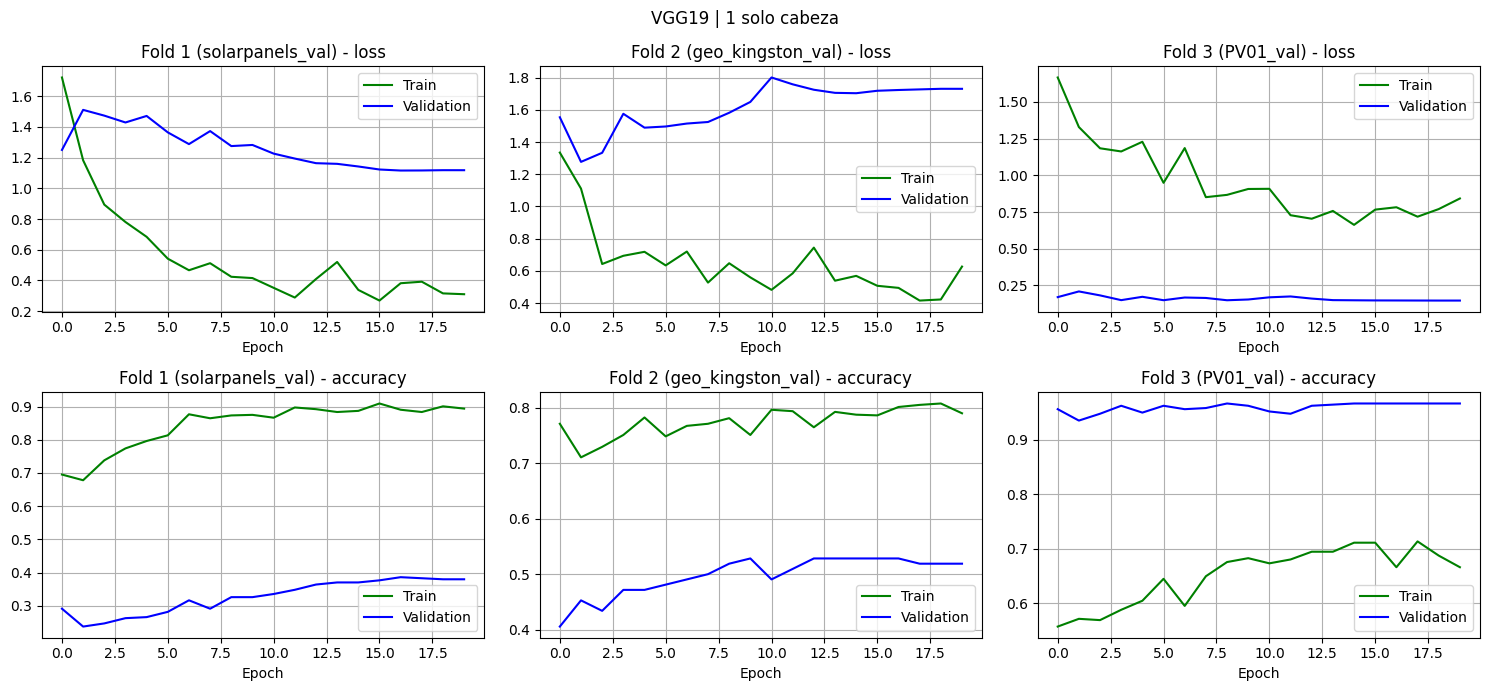

               modelo                 fold  loss  accuracy   auc  accuracy_balanceada  recall_pos  recall_neg  tn  fp  fn  tp
VGG19 | 1 solo cabeza  1 (solarpanels_val) 1.118     0.380 0.592                0.544       0.338       0.750  24   8 188  96
VGG19 | 1 solo cabeza 2 (geo_kingston_val) 1.731     0.519 0.612                0.582       0.955       0.210  13  49   2  42
VGG19 | 1 solo cabeza         3 (PV01_val) 0.146     0.967 0.733                0.484       0.969       0.000   0   1  15 462

Promedio folds 1 y 2:
auc                    0.602
accuracy_balanceada    0.563
recall_pos             0.646
recall_neg             0.480
Recall positivas fold 3: 0.969

===== VGG19 | 2 ft último bloque | lr 1e-05 | 20 épocas | Fold 1 (solarpanels_val) =====


Model: "VGG19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento (Lambda)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,090,177 (76.64 MB)

 Trainable params: 9,505,025 (36.26 MB)

 Non-trainable params: 10,585,152 (40.38 MB)

Epoch 1/20
19/19 - 21s - 1s/step - accuracy: 0.7312 - auc: 0.7445 - loss: 0.9876 - val_accuracy: 0.1519 - val_auc: 0.5359 - val_loss: 1.7484
Epoch 2/20
19/19 - 6s - 327ms/step - accuracy: 0.8288 - auc: 0.9214 - loss: 0.4288 - val_accuracy: 0.5633 - val_auc: 0.6067 - val_loss: 0.7150
Epoch 3/20
19/19 - 6s - 334ms/step - accuracy: 0.9110 - auc: 0.9582 - loss: 0.2655 - val_accuracy: 0.4968 - val_auc: 0.5922 - val_loss: 0.8050
Epoch 4/20
19/19 - 6s - 340ms/step - accuracy: 0.9161 - auc: 0.9643 - loss: 0.2291 - val_accuracy: 0.6329 - val_auc: 0.6011 - val_loss: 0.6585
Epoch 5/20
19/19 - 6s - 336ms/step - accuracy: 0.9315 - auc: 0.9767 - loss: 0.1764 - val_accuracy: 0.6139 - val_auc: 0.6036 - val_loss: 0.6876
Epoch 6/20
19/19 - 6s - 331ms/step - accuracy: 0.9452 - auc: 0.9860 - loss: 0.1302 - val_accuracy: 0.6361 - val_auc: 0.6131 - val_loss: 0.6561
Epoch 7/20
19/19 - 6s - 326ms/step - accuracy: 0.9521 - auc: 0.9874 - loss: 0.1305 - val_accuracy: 0.6994 - val_auc: 0.6268 - val_loss: 0.5910
E

Fold 3: acc 0.981 | AUC 0.945 | recall pos 0.983 | recall neg 0.000 | TN 0 FP 1 FN 8 TP 469


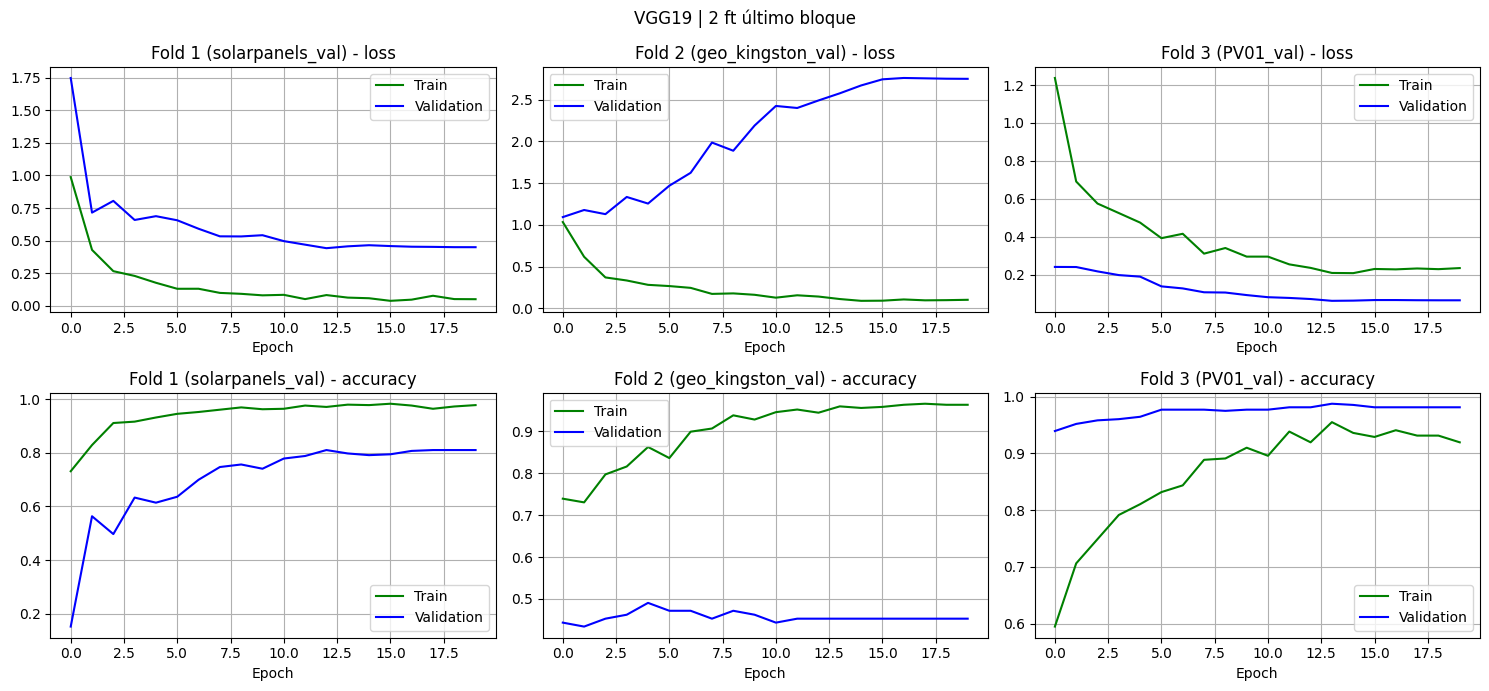

                    modelo                 fold  loss  accuracy   auc  accuracy_balanceada  recall_pos  recall_neg  tn  fp  fn  tp
VGG19 | 2 ft último bloque  1 (solarpanels_val) 0.449     0.810 0.646                0.589       0.866       0.312  10  22  38 246
VGG19 | 2 ft último bloque 2 (geo_kingston_val) 2.750     0.453 0.668                0.532       1.000       0.065   4  58   0  44
VGG19 | 2 ft último bloque         3 (PV01_val) 0.064     0.981 0.945                0.492       0.983       0.000   0   1   8 469

Promedio folds 1 y 2:
auc                    0.657
accuracy_balanceada    0.561
recall_pos             0.933
recall_neg             0.189
Recall positivas fold 3: 0.983

===== VGG19 | 3 ft último bloque + aug | lr 1e-05 | 20 épocas | Fold 1 (solarpanels_val) =====


Model: "VGG19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentacion (Sequential)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento (Lambda)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,090,177 (76.64 MB)

 Trainable params: 9,505,025 (36.26 MB)

 Non-trainable params: 10,585,152 (40.38 MB)

Epoch 1/20
19/19 - 29s - 2s/step - accuracy: 0.6712 - auc: 0.6878 - loss: 1.0786 - val_accuracy: 0.6487 - val_auc: 0.4890 - val_loss: 0.6487
Epoch 2/20
19/19 - 7s - 346ms/step - accuracy: 0.7192 - auc: 0.8492 - loss: 0.5729 - val_accuracy: 0.5506 - val_auc: 0.5178 - val_loss: 0.7223
Epoch 3/20
19/19 - 6s - 341ms/step - accuracy: 0.8219 - auc: 0.9036 - loss: 0.4212 - val_accuracy: 0.7753 - val_auc: 0.5668 - val_loss: 0.5230
Epoch 4/20
19/19 - 6s - 341ms/step - accuracy: 0.8442 - auc: 0.9231 - loss: 0.3617 - val_accuracy: 0.7943 - val_auc: 0.5843 - val_loss: 0.5049
Epoch 5/20
19/19 - 6s - 336ms/step - accuracy: 0.8527 - auc: 0.9217 - loss: 0.3649 - val_accuracy: 0.7057 - val_auc: 0.5908 - val_loss: 0.5662
Epoch 6/20
19/19 - 6s - 336ms/step - accuracy: 0.8630 - auc: 0.9442 - loss: 0.3140 - val_accuracy: 0.7405 - val_auc: 0.6023 - val_loss: 0.5442
Epoch 7/20
19/19 - 6s - 335ms/step - accuracy: 0.8836 - auc: 0.9539 - loss: 0.2657 - val_accuracy: 0.8418 - val_auc: 0.6193 - val_loss: 0.4257
E

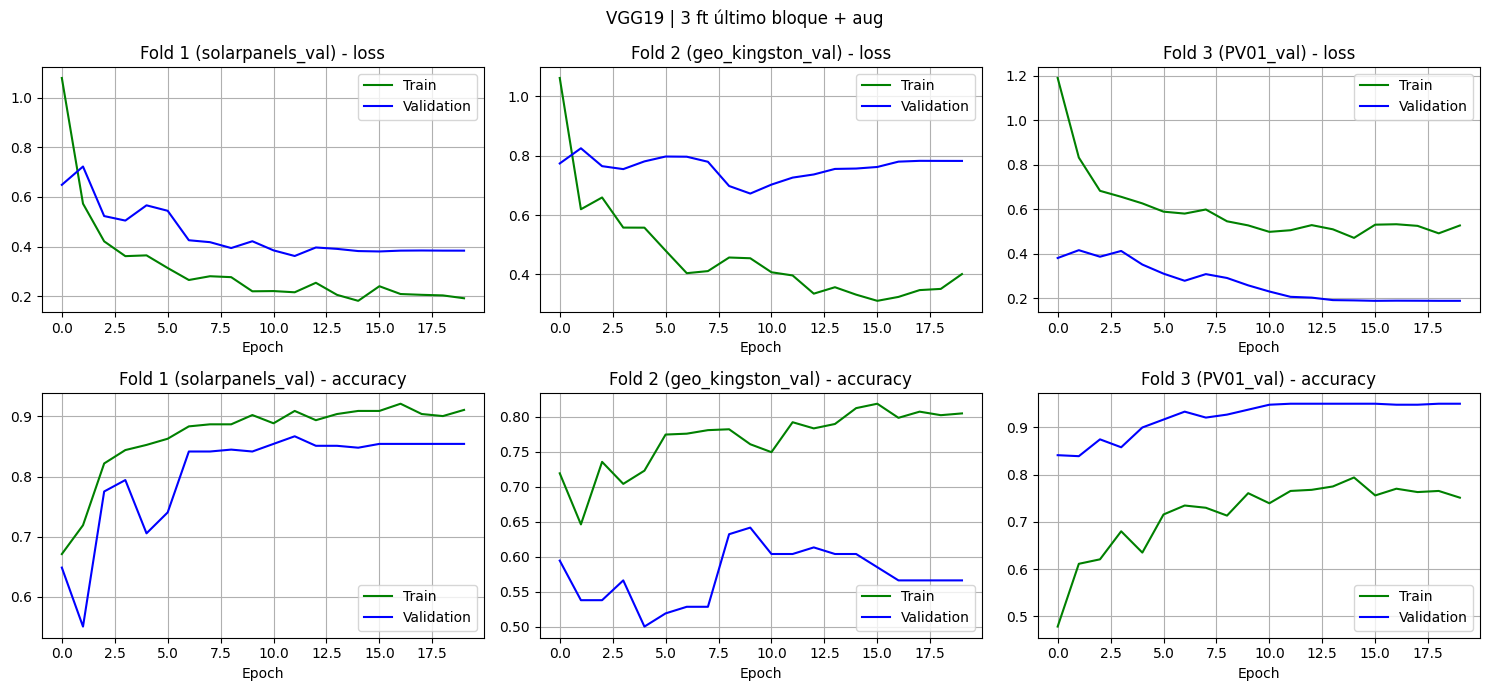

                          modelo                 fold  loss  accuracy   auc  accuracy_balanceada  recall_pos  recall_neg  tn  fp  fn  tp
VGG19 | 3 ft último bloque + aug  1 (solarpanels_val) 0.384     0.854 0.642                0.600       0.919       0.281   9  23  23 261
VGG19 | 3 ft último bloque + aug 2 (geo_kingston_val) 0.782     0.566 0.666                0.583       0.682       0.484  30  32  14  30
VGG19 | 3 ft último bloque + aug         3 (PV01_val) 0.189     0.950 0.933                0.476       0.952       0.000   0   1  23 454

Promedio folds 1 y 2:
auc                    0.654
accuracy_balanceada    0.591
recall_pos             0.800
recall_neg             0.383
Recall positivas fold 3: 0.952

===== VGG19 | 4 secuencial + aug | Fold 1 (solarpanels_val) | fase 0: solo cabeza | 0 capas del extractor entrenables | lr 0.0001 | 10 épocas =====
Epoch 1/10
19/19 - 8s - 438ms/step - accuracy: 0.6062 - auc: 0.5691 - loss: 1.6711 - val_accuracy: 0.4051 - val_auc: 0.4448 - val_los

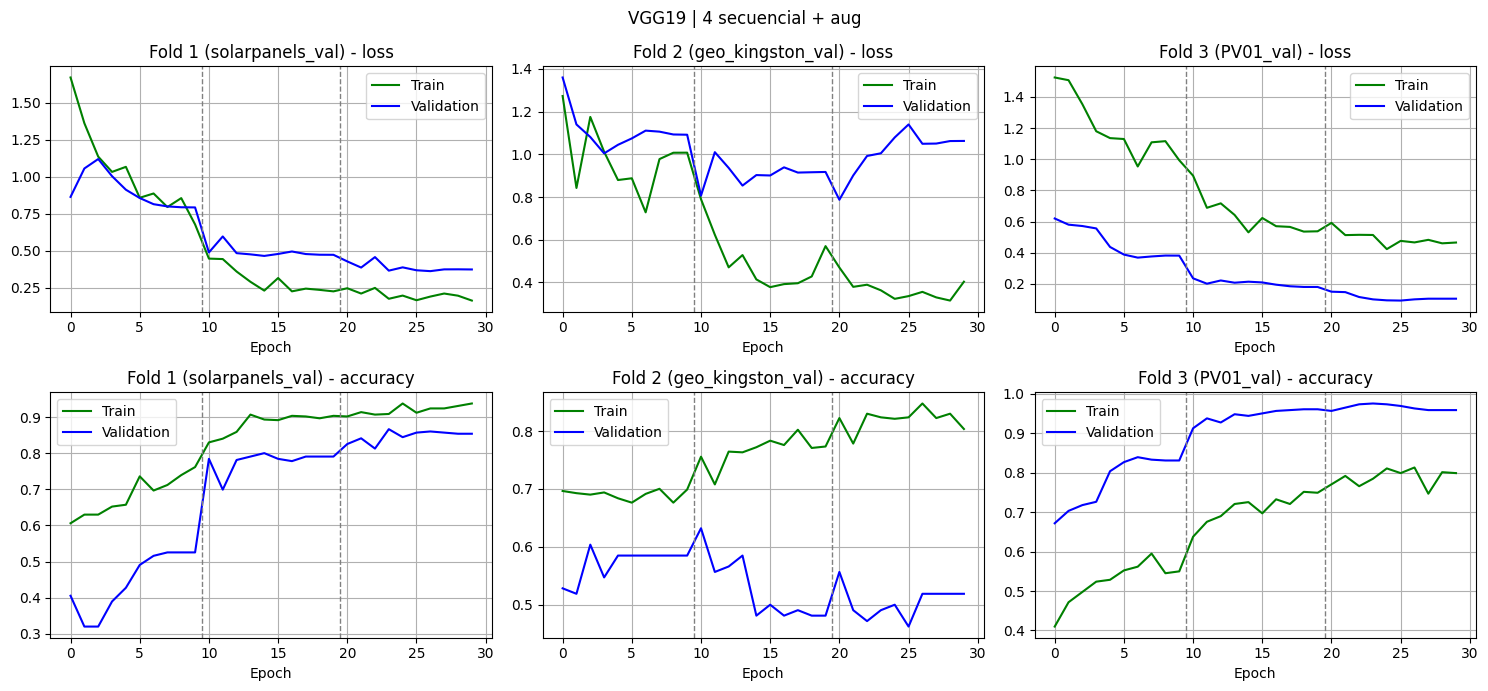

                    modelo                 fold  loss  accuracy   auc  accuracy_balanceada  recall_pos  recall_neg  tn  fp  fn  tp
VGG19 | 4 secuencial + aug  1 (solarpanels_val) 0.374     0.854 0.657                0.586       0.923       0.250   8  24  22 262
VGG19 | 4 secuencial + aug 2 (geo_kingston_val) 1.063     0.519 0.720                0.576       0.909       0.242  15  47   4  40
VGG19 | 4 secuencial + aug         3 (PV01_val) 0.105     0.958 0.908                0.480       0.960       0.000   0   1  19 458

Promedio folds 1 y 2:
auc                    0.689
accuracy_balanceada    0.581
recall_pos             0.916
recall_neg             0.246
Recall positivas fold 3: 0.960


In [ ]:
correr_experimentos("VGG19")

## ResNet50


===== ResNet50 | 1 solo cabeza | lr 0.0001 | 20 épocas | Fold 1 (solarpanels_val) =====
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento (Lambda)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/20
19/19 - 61s - 3s/step - accuracy: 0.7021 - auc: 0.7630 - loss: 0.6394 - val_accuracy: 0.8956 - val_auc: 0.7361 - val_loss: 0.3386
Epoch 2/20
19/19 - 29s - 2s/step - accuracy: 0.8836 - auc: 0.9398 - loss: 0.3121 - val_accuracy: 0.7848 - val_auc: 0.7144 - val_loss: 0.4922
Epoch 3/20
19/19 - 3s - 132ms/step - accuracy: 0.9041 - auc: 0.9704 - loss: 0.2114 - val_accuracy: 0.8734 - val_auc: 0.7205 - val_loss: 0.3506
Epoch 4/20
19/19 - 3s - 155ms/step - accuracy: 0.9264 - auc: 0.9677 - loss: 0.2168 - val_accuracy: 0.8956 - val_auc: 0.7227 - val_loss: 0.3214
Epoch 5/20
19/19 - 5s - 251ms/step - accuracy: 0.9332 - auc: 0.9752 - loss: 0.1842 - val_accuracy: 0.8924 - val_auc: 0.7241 - val_loss: 0.3127
Epoch 6/20
19/19 - 3s - 136ms/step - accuracy: 0.9332 - auc: 0.9767 - loss: 0.1684 - val_accuracy: 0.8956 - val_auc: 0.7278 - val_loss: 0.2997
Epoch 7/20
19/19 - 3s - 137ms/step - accuracy: 0.9401 - auc: 0.9825 - loss: 0.1609 - val_accuracy: 0.8987 - val_auc: 0.7192 - val_loss: 0.3037
Epo

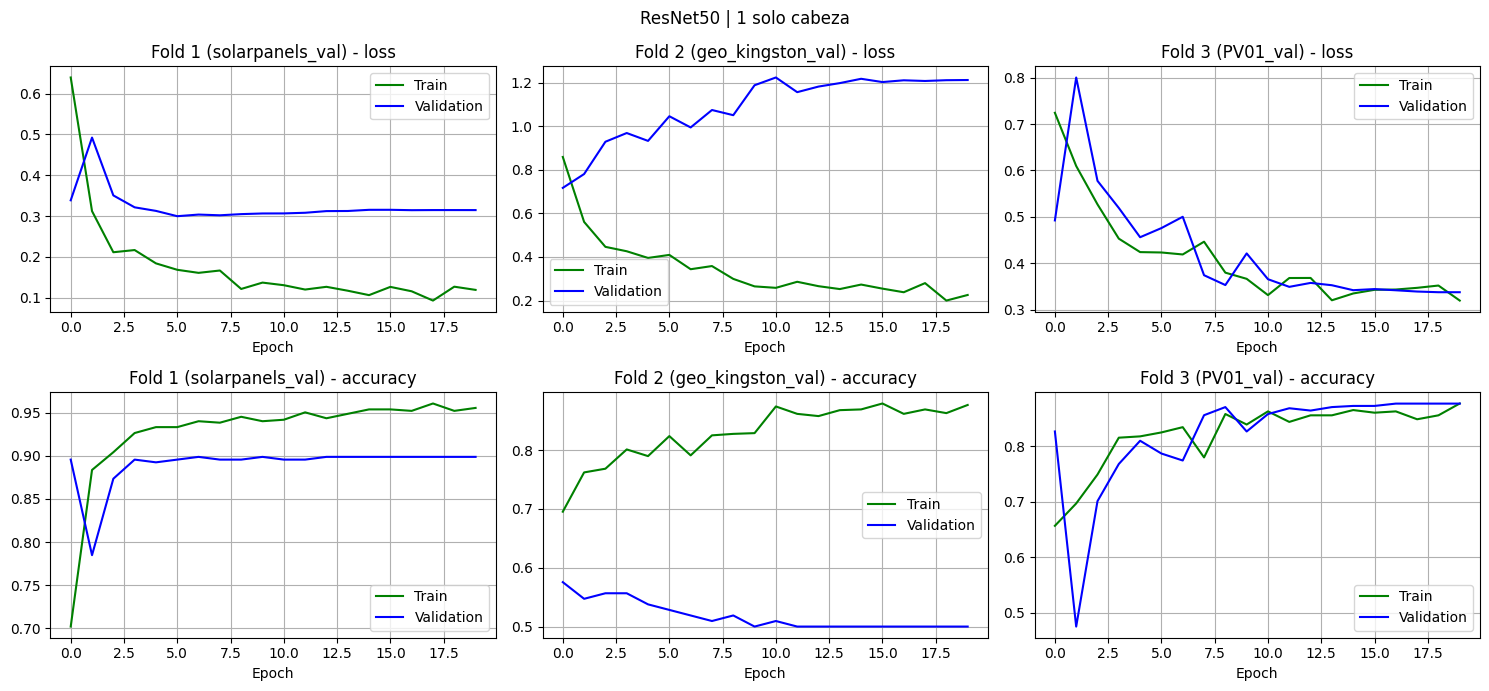

                  modelo                 fold  loss  accuracy   auc  accuracy_balanceada  recall_pos  recall_neg  tn  fp  fn  tp
ResNet50 | 1 solo cabeza  1 (solarpanels_val) 0.315     0.899 0.715                0.500       1.000       0.000   0  32   0 284
ResNet50 | 1 solo cabeza 2 (geo_kingston_val) 1.212     0.500 0.697                0.569       0.977       0.161  10  52   1  43
ResNet50 | 1 solo cabeza         3 (PV01_val) 0.338     0.877 0.922                0.938       0.876       1.000   1   0  59 418

Promedio folds 1 y 2:
auc                    0.706
accuracy_balanceada    0.535
recall_pos             0.989
recall_neg             0.081
Recall positivas fold 3: 0.876

===== ResNet50 | 2 ft último bloque | lr 1e-05 | 20 épocas | Fold 1 (solarpanels_val) =====


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento (Lambda)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 15,215,873 (58.04 MB)

 Non-trainable params: 8,634,240 (32.94 MB)

Epoch 1/20
19/19 - 38s - 2s/step - accuracy: 0.6062 - auc: 0.7637 - loss: 0.6314 - val_accuracy: 0.8449 - val_auc: 0.7075 - val_loss: 0.4749
Epoch 2/20
19/19 - 3s - 172ms/step - accuracy: 0.8750 - auc: 0.9556 - loss: 0.2830 - val_accuracy: 0.7627 - val_auc: 0.7048 - val_loss: 0.5510
Epoch 3/20
19/19 - 4s - 191ms/step - accuracy: 0.9298 - auc: 0.9774 - loss: 0.1832 - val_accuracy: 0.8608 - val_auc: 0.7197 - val_loss: 0.3664
Epoch 4/20
19/19 - 3s - 169ms/step - accuracy: 0.9418 - auc: 0.9804 - loss: 0.1640 - val_accuracy: 0.8956 - val_auc: 0.7257 - val_loss: 0.3045
Epoch 5/20
19/19 - 3s - 170ms/step - accuracy: 0.9503 - auc: 0.9891 - loss: 0.1268 - val_accuracy: 0.8956 - val_auc: 0.7258 - val_loss: 0.2988
Epoch 6/20
19/19 - 3s - 175ms/step - accuracy: 0.9589 - auc: 0.9919 - loss: 0.0985 - val_accuracy: 0.8987 - val_auc: 0.7410 - val_loss: 0.3190
Epoch 7/20
19/19 - 3s - 172ms/step - accuracy: 0.9658 - auc: 0.9951 - loss: 0.0782 - val_accuracy: 0.8987 - val_auc: 0.7460 - val_loss: 0.3281
E

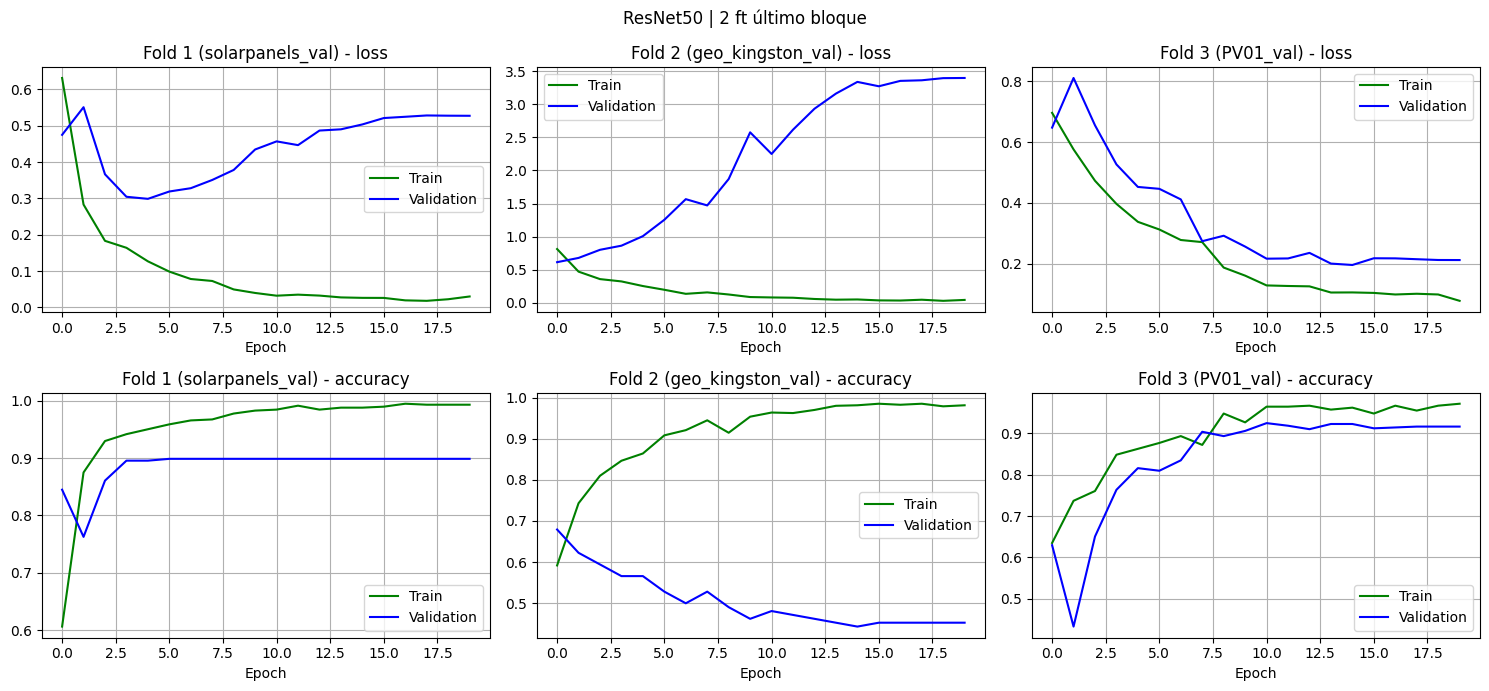

                       modelo                 fold  loss  accuracy   auc  accuracy_balanceada  recall_pos  recall_neg  tn  fp  fn  tp
ResNet50 | 2 ft último bloque  1 (solarpanels_val) 0.527     0.899 0.729                0.500       1.000       0.000   0  32   0 284
ResNet50 | 2 ft último bloque 2 (geo_kingston_val) 3.395     0.453 0.679                0.532       1.000       0.065   4  58   0  44
ResNet50 | 2 ft último bloque         3 (PV01_val) 0.212     0.916 0.917                0.459       0.918       0.000   0   1  39 438

Promedio folds 1 y 2:
auc                    0.704
accuracy_balanceada    0.516
recall_pos             1.000
recall_neg             0.032
Recall positivas fold 3: 0.918

===== ResNet50 | 3 ft último bloque + aug | lr 1e-05 | 20 épocas | Fold 1 (solarpanels_val) =====


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentacion (Sequential)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento (Lambda)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 15,215,873 (58.04 MB)

 Non-trainable params: 8,634,240 (32.94 MB)

Epoch 1/20
19/19 - 25s - 1s/step - accuracy: 0.6233 - auc: 0.6778 - loss: 0.6827 - val_accuracy: 0.7816 - val_auc: 0.6063 - val_loss: 0.5664
Epoch 2/20
19/19 - 5s - 279ms/step - accuracy: 0.8065 - auc: 0.8883 - loss: 0.4310 - val_accuracy: 0.8418 - val_auc: 0.6530 - val_loss: 0.4894
Epoch 3/20
19/19 - 5s - 285ms/step - accuracy: 0.8613 - auc: 0.9338 - loss: 0.3287 - val_accuracy: 0.8956 - val_auc: 0.6714 - val_loss: 0.3794
Epoch 4/20
19/19 - 5s - 284ms/step - accuracy: 0.8955 - auc: 0.9533 - loss: 0.2787 - val_accuracy: 0.9051 - val_auc: 0.6871 - val_loss: 0.3389
Epoch 5/20
19/19 - 5s - 288ms/step - accuracy: 0.9195 - auc: 0.9648 - loss: 0.2344 - val_accuracy: 0.9019 - val_auc: 0.6940 - val_loss: 0.3273
Epoch 6/20
19/19 - 5s - 281ms/step - accuracy: 0.9127 - auc: 0.9690 - loss: 0.2130 - val_accuracy: 0.8987 - val_auc: 0.6978 - val_loss: 0.3120
Epoch 7/20
19/19 - 5s - 282ms/step - accuracy: 0.9332 - auc: 0.9755 - loss: 0.1863 - val_accuracy: 0.8987 - val_auc: 0.6947 - val_loss: 0.3106
E

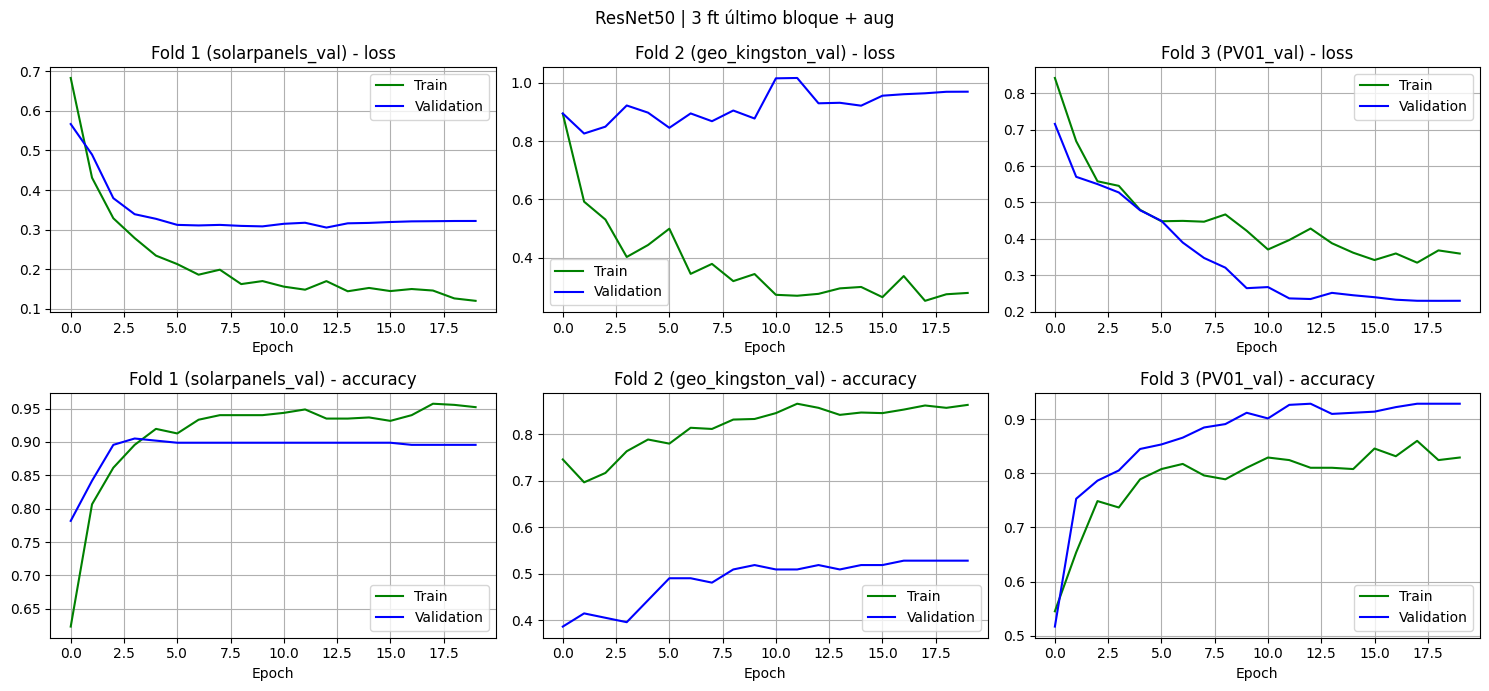

                             modelo                 fold  loss  accuracy   auc  accuracy_balanceada  recall_pos  recall_neg  tn  fp  fn  tp
ResNet50 | 3 ft último bloque + aug  1 (solarpanels_val) 0.322     0.896 0.729                0.498       0.996       0.000   0  32   1 283
ResNet50 | 3 ft último bloque + aug 2 (geo_kingston_val) 0.969     0.528 0.738                0.593       0.977       0.210  13  49   1  43
ResNet50 | 3 ft último bloque + aug         3 (PV01_val) 0.230     0.929 0.790                0.465       0.931       0.000   0   1  33 444

Promedio folds 1 y 2:
auc                    0.734
accuracy_balanceada    0.546
recall_pos             0.987
recall_neg             0.105
Recall positivas fold 3: 0.931

===== ResNet50 | 4 secuencial + aug | Fold 1 (solarpanels_val) | fase 0: solo cabeza | 0 capas del extractor entrenables | lr 0.0001 | 10 épocas =====
Epoch 1/10
19/19 - 15s - 776ms/step - accuracy: 0.6404 - auc: 0.6909 - loss: 0.6789 - val_accuracy: 0.8196 - val_auc: 

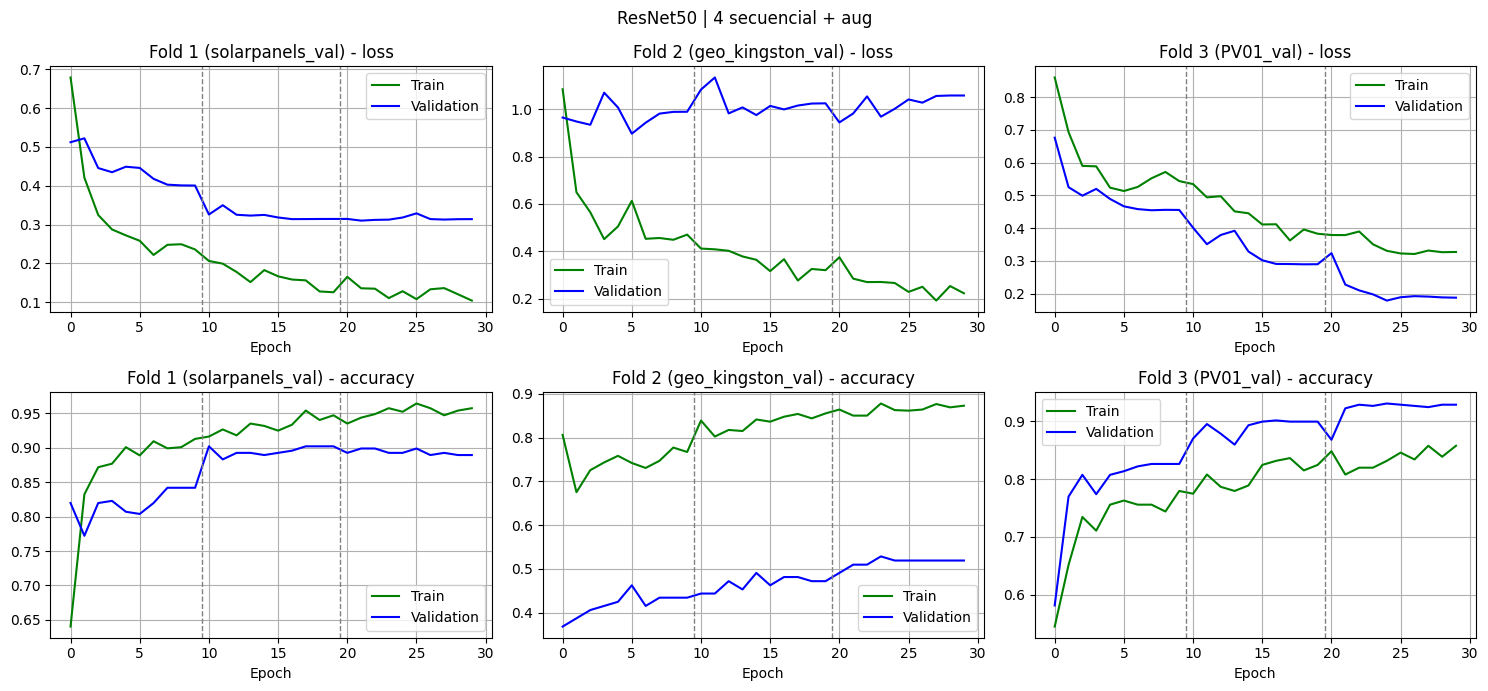

                       modelo                 fold  loss  accuracy   auc  accuracy_balanceada  recall_pos  recall_neg  tn  fp  fn  tp
ResNet50 | 4 secuencial + aug  1 (solarpanels_val) 0.314     0.889 0.729                0.522       0.982       0.062   2  30   5 279
ResNet50 | 4 secuencial + aug 2 (geo_kingston_val) 1.058     0.519 0.693                0.576       0.909       0.242  15  47   4  40
ResNet50 | 4 secuencial + aug         3 (PV01_val) 0.187     0.929 0.836                0.465       0.931       0.000   0   1  33 444

Promedio folds 1 y 2:
auc                    0.711
accuracy_balanceada    0.549
recall_pos             0.946
recall_neg             0.152
Recall positivas fold 3: 0.931


In [ ]:
correr_experimentos("ResNet50")

# Mejor umbral de cada modelo

Para cada experimento se busca el umbral (entre 0,05 y 0,95, de a 0,01) que maximiza la balanced accuracy con las
predicciones de los 3 folds juntas.

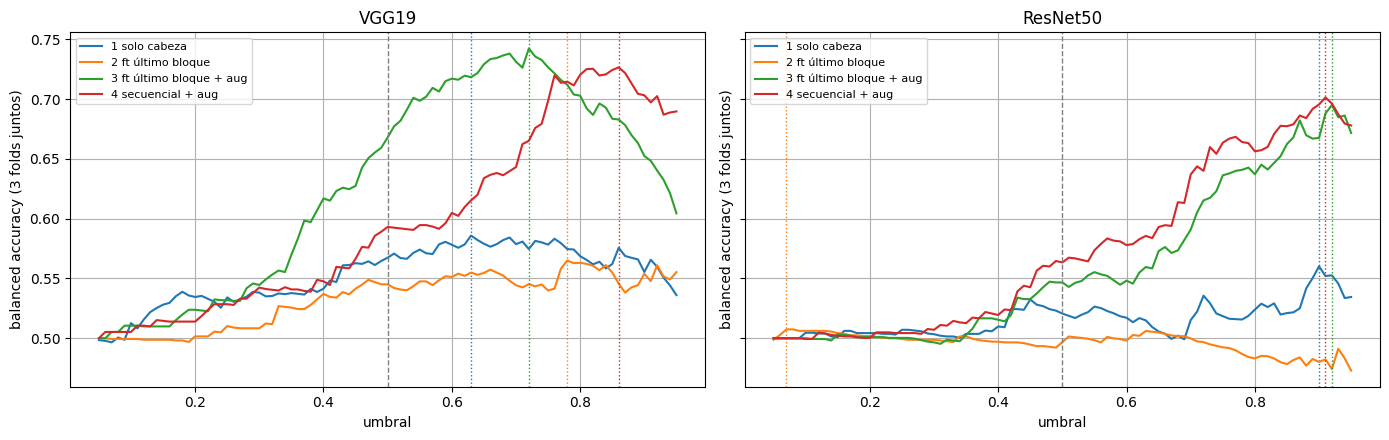

                             modelo  mejor_umbral  balanced_accuracy_05  f1_05  balanced_accuracy_mejor  f1_mejor
              VGG19 | 1 solo cabeza         0.630                 0.567  0.820                    0.586     0.780
         VGG19 | 2 ft último bloque         0.780                 0.545  0.923                    0.565     0.854
   VGG19 | 3 ft último bloque + aug         0.720                 0.668  0.928                    0.742     0.865
         VGG19 | 4 secuencial + aug         0.860                 0.593  0.929                    0.727     0.839
           ResNet50 | 1 solo cabeza         0.900                 0.521  0.912                    0.560     0.629
      ResNet50 | 2 ft último bloque         0.070                 0.497  0.922                    0.507     0.942
ResNet50 | 3 ft último bloque + aug         0.920                 0.547  0.929                    0.695     0.747
      ResNet50 | 4 secuencial + aug         0.910                 0.563  0.927          

In [ ]:
NOMBRES = [nombre for red in ("VGG19", "ResNet50") for nombre, _, _ in experimentos_de(red)]
UMBRALES = {nombre: mejor_umbral(nombre) for nombre in NOMBRES}

# Balanced accuracy según el umbral, una curva por experimento
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, red in zip(axes, ("VGG19", "ResNet50")):
    for nombre in NOMBRES:
        if nombre.startswith(red):
            tabla = barrer_umbral(nombre)
            linea, = ax.plot(tabla.umbral, tabla.balanced_accuracy, label=nombre.split(" | ")[1])
            ax.axvline(UMBRALES[nombre], color=linea.get_color(), linestyle=":", linewidth=1)
    ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_title(red)
    ax.set_xlabel("umbral")
    ax.set_ylabel("balanced accuracy (3 folds juntos)")
    ax.grid(True)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

filas = []
for nombre in NOMBRES:
    con_05 = _metricas(*predicciones_juntas(nombre), 0.5)
    con_mejor = _metricas(*predicciones_juntas(nombre), UMBRALES[nombre])
    filas.append(dict(modelo=nombre, mejor_umbral=UMBRALES[nombre],
                      balanced_accuracy_05=con_05["balanced_accuracy"], f1_05=con_05["f1"],
                      balanced_accuracy_mejor=con_mejor["balanced_accuracy"], f1_mejor=con_mejor["f1"]))
tabla_umbrales = pd.DataFrame(filas)
print(tabla_umbrales.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# Comparación de modelos

Cada modelo con su mejor umbral, comparado con **balanced accuracy** y **F1**:

- **3 folds juntos**: las 900 imágenes con el umbral elegido. Es el criterio con el que se eligió el umbral.
- **Promedio folds 1 y 2**: cómo le va con cada fuente nueva por separado. El fold 3 queda afuera porque su
  validación tiene una sola imagen sin paneles.

La tabla se guarda en `comparacion_modelos.csv`. Para ver el detalle por fold de un modelo:
`metricas_umbral(nombre, UMBRALES[nombre])`.

     red            configuracion  umbral  balanced_accuracy    f1  balanced_accuracy_f12  f1_f12
   VGG19 3 ft último bloque + aug   0.720              0.742 0.865                  0.657   0.726
   VGG19       4 secuencial + aug   0.860              0.727 0.839                  0.649   0.682
ResNet50       4 secuencial + aug   0.910              0.701 0.799                  0.659   0.715
ResNet50 3 ft último bloque + aug   0.920              0.695 0.747                  0.690   0.745
   VGG19            1 solo cabeza   0.630              0.586 0.780                  0.585   0.491
   VGG19       2 ft último bloque   0.780              0.565 0.854                  0.594   0.650
ResNet50            1 solo cabeza   0.900              0.560 0.629                  0.662   0.742
ResNet50       2 ft último bloque   0.070              0.507 0.942                  0.508   0.771


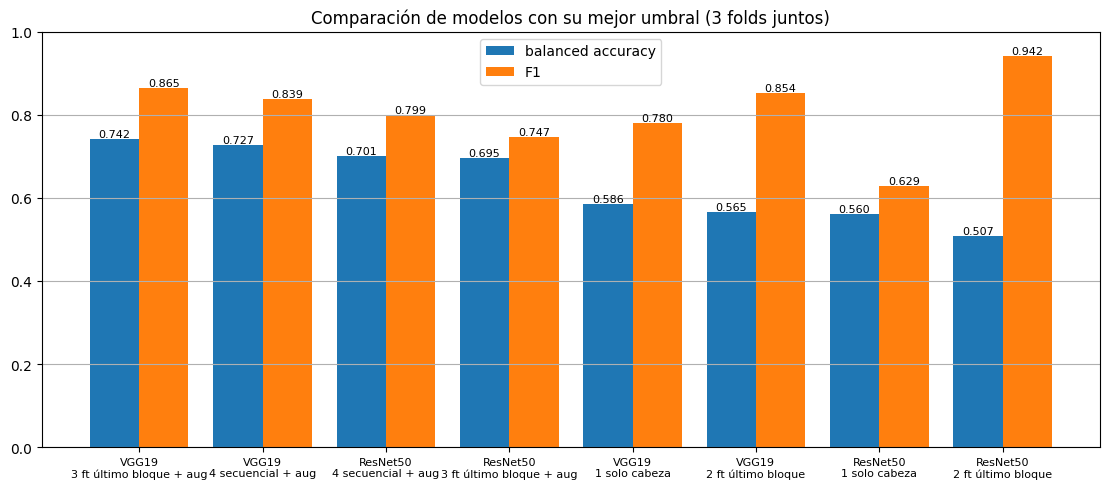

In [ ]:
filas = []
for nombre in NOMBRES:
    tabla = metricas_umbral(nombre, UMBRALES[nombre], mostrar=False)
    juntos = tabla[tabla.fold == "todos juntos"].iloc[0]
    f12 = tabla[tabla.fold.str[0].isin(["1", "2"])]
    filas.append(dict(
        red=nombre.split(" | ")[0], configuracion=nombre.split(" | ")[1], umbral=UMBRALES[nombre],
        balanced_accuracy=juntos.balanced_accuracy, f1=juntos.f1,
        balanced_accuracy_f12=f12.balanced_accuracy.mean(), f1_f12=f12.f1.mean(),
    ))
comparacion = pd.DataFrame(filas).sort_values("balanced_accuracy", ascending=False)
comparacion.to_csv("comparacion_modelos.csv", index=False)
print(comparacion.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# Gráfico: balanced accuracy y F1 (3 folds juntos) de cada modelo con su mejor umbral
orden = comparacion.assign(etiqueta=comparacion.red + "\n" + comparacion.configuracion)
x = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(max(10, 1.4 * len(orden)), 5))
barras_ba = ax.bar(x - 0.2, orden.balanced_accuracy, width=0.4, label="balanced accuracy")
barras_f1 = ax.bar(x + 0.2, orden.f1, width=0.4, label="F1")
ax.bar_label(barras_ba, fmt="%.3f", fontsize=8)
ax.bar_label(barras_f1, fmt="%.3f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(orden.etiqueta, fontsize=8)
ax.set_ylim(0, 1)
ax.set_title("Comparación de modelos con su mejor umbral (3 folds juntos)")
ax.legend()
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image

DIR_TEST = Path("data/test")   # dentro del repo: etiquetas.csv y lote_1 ... lote_5

if not (DIR_TEST / "etiquetas.csv").is_file():
    raise FileNotFoundError(f"No encontré {DIR_TEST / 'etiquetas.csv'}. ¿Está subida la carpeta data/test al repo?")

ETIQUETAS_TEST = pd.read_csv(DIR_TEST / "etiquetas.csv")
faltan = [a for a in ETIQUETAS_TEST.archivo if not (DIR_TEST / a).is_file()]
if faltan:
    raise FileNotFoundError(f"Faltan {len(faltan)} imágenes del test en {DIR_TEST}, por ejemplo: {faltan[:3]}")

X_test = np.stack([cargar_rgb(DIR_TEST / a) for a in ETIQUETAS_TEST.archivo])
y_test = (ETIQUETAS_TEST.etiqueta.str.strip().str.lower() == "con").astype(int).to_numpy()
print(f"Test: {len(y_test)} imágenes | {y_test.sum()} con paneles | {len(y_test) - y_test.sum()} sin paneles")

lote_1 -> 40 imágenes
lote_2 -> 40 imágenes
lote_3 -> 40 imágenes
lote_4 -> 40 imágenes
lote_5 -> 40 imágenes

200 imágenes en etiquetas.csv | faltan: 0


VGG19 | 3 ft último bloque + aug | umbral elegido en cross validation: 0.72
Entrenamiento: 900 imágenes | 805 con paneles | 95 sin paneles
Epoch 1/20
29/29 - 10s - 331ms/step - accuracy: 0.6478 - auc: 0.6528 - loss: 1.0465
Epoch 2/20
29/29 - 7s - 242ms/step - accuracy: 0.6822 - auc: 0.7370 - loss: 0.6769
Epoch 3/20
29/29 - 8s - 269ms/step - accuracy: 0.7156 - auc: 0.8461 - loss: 0.4825
Epoch 4/20
29/29 - 7s - 239ms/step - accuracy: 0.7556 - auc: 0.8574 - loss: 0.4563
Epoch 5/20
29/29 - 7s - 237ms/step - accuracy: 0.7978 - auc: 0.8822 - loss: 0.4188
Epoch 6/20
29/29 - 7s - 231ms/step - accuracy: 0.7989 - auc: 0.8877 - loss: 0.4192
Epoch 7/20
29/29 - 7s - 236ms/step - accuracy: 0.7867 - auc: 0.9084 - loss: 0.3675
Epoch 8/20
29/29 - 7s - 226ms/step - accuracy: 0.8322 - auc: 0.9235 - loss: 0.3461
Epoch 9/20
29/29 - 7s - 228ms/step - accuracy: 0.8200 - auc: 0.9179 - loss: 0.3465
Epoch 10/20
29/29 - 7s - 226ms/step - accuracy: 0.8278 - auc: 0.9134 - loss: 0.3637
Epoch 11/20
29/29 - 7s - 228m

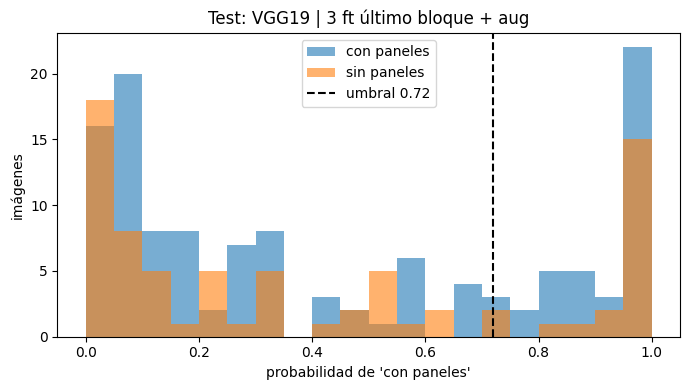

In [ ]:
# =========================================================
# Modelo final: entrenar la configuración elegida con las 900 imágenes y evaluar en el test
# =========================================================
from PIL import Image

NOMBRE_FINAL = "VGG19 | 3 ft último bloque + aug"      # la de mayor balanced accuracy en la comparación
DIR_TEST = Path("/content/test_paneles_200")  # carpeta con etiquetas.csv y lote_1 ... lote_5

# --- 1) Configuración y umbral elegidos con el cross validation (no se tocan después de ver el test)
config_final = {n: (f, kw) for red in ("VGG19", "ResNet50") for n, f, kw in experimentos_de(red)}
funcion_final, kwargs_final = config_final[NOMBRE_FINAL]
UMBRAL_FINAL = UMBRALES[NOMBRE_FINAL]
print(f"{NOMBRE_FINAL} | umbral elegido en cross validation: {UMBRAL_FINAL:.2f}")

# --- 2) Las 900 imágenes: el train y la validación de cualquier fold juntos
X_todo = np.concatenate([X_train_1, X_val_1])
y_todo = np.concatenate([y_train_1, y_val_1])
n, n_pos = len(y_todo), int(y_todo.sum())
pesos = {0: n / (2 * (n - n_pos)), 1: n / (2 * n_pos)}
print(f"Entrenamiento: {n} imágenes | {n_pos} con paneles | {n - n_pos} sin paneles")

# --- 3) Entrenamiento (sin validación: todos los datos van al train)
keras.backend.clear_session()
keras.utils.set_random_seed(SEED_VALUE)
red = kwargs_final["red"]
if funcion_final is entrenar_folds_secuencial:
    fases = kwargs_final["fases"]
    modelo_final = construir_modelo(red, fine_tune=0, lr=fases[0]["lr"], epocas=fases[0]["epocas"],
                                    n_train=n, augmentar=kwargs_final["augmentar"])
    base = extractor_de(modelo_final)
    epoca = 0
    for fase in fases:
        b = fase["bloques"]
        configurar_entrenables(base, red, 0 if b == 0 else BLOQUES[red][b - 1])
        compilar(modelo_final, fase["lr"], fase["epocas"], n)
        modelo_final.fit(X_todo, y_todo, initial_epoch=epoca, epochs=epoca + fase["epocas"],
                         batch_size=TrainingConfig.BATCH_SIZE, class_weight=pesos, shuffle=True, verbose=2)
        epoca += fase["epocas"]
else:
    modelo_final = construir_modelo(red, kwargs_final["fine_tune"], lr=kwargs_final["lr"],
                                    epocas=kwargs_final["epocas"], n_train=n, augmentar=kwargs_final["augmentar"])
    modelo_final.fit(X_todo, y_todo, epochs=kwargs_final["epocas"], batch_size=TrainingConfig.BATCH_SIZE,
                     class_weight=pesos, shuffle=True, verbose=2)
modelo_final.save_weights(str(DIR_CV / "modelo_final.weights.h5"))

# --- 4) Test: imágenes y etiquetas (etiquetas.csv: archivo, etiqueta con/sin)
etiquetas = pd.read_csv(DIR_TEST / "etiquetas.csv")
faltan = [a for a in etiquetas.archivo if not (DIR_TEST / a).is_file()]
if faltan:
    raise FileNotFoundError(f"Faltan {len(faltan)} imágenes del test en {DIR_TEST}, por ejemplo: {faltan[:3]}")

TAM = (DatasetConfig.IMG_WIDTH, DatasetConfig.IMG_HEIGHT)
def cargar_test(ruta):
    with Image.open(ruta) as im:
        im = im.convert("RGB")
        reescalada = im.size != TAM
        if reescalada:
            im = im.resize(TAM, Image.BILINEAR)
        return np.array(im), reescalada

cargadas = [cargar_test(DIR_TEST / a) for a in etiquetas.archivo]
X_test = np.stack([img for img, _ in cargadas])
y_test = (etiquetas.etiqueta.str.strip().str.lower() == "con").astype(int).to_numpy()
n_reesc = sum(r for _, r in cargadas)
print(f"\nTest: {len(y_test)} imágenes | {y_test.sum()} con paneles | {len(y_test) - y_test.sum()} sin paneles"
      + (f" | {n_reesc} reescaladas a {TAM[0]}x{TAM[1]}" if n_reesc else ""))

# --- 5) Predicción y métricas con el umbral del cross validation (y con 0,5 como referencia)
prob_test = modelo_final.predict(X_test, batch_size=TrainingConfig.BATCH_SIZE, verbose=0).ravel()
etiquetas["lote"] = etiquetas.archivo.str.split("/").str[0]
etiquetas["prob"] = prob_test
etiquetas["pred"] = np.where(prob_test >= UMBRAL_FINAL, "con", "sin")
etiquetas.to_csv(DIR_CV / "predicciones_test.csv", index=False)

filas = [dict(conjunto=f"test (umbral {u:.2f})", **_metricas(y_test, prob_test, u)) for u in (UMBRAL_FINAL, 0.5)]
for lote, sub in etiquetas.groupby("lote"):
    y_l = (sub.etiqueta.str.strip().str.lower() == "con").astype(int)
    filas.append(dict(conjunto=f"{lote} (umbral {UMBRAL_FINAL:.2f})", **_metricas(y_l, sub.prob, UMBRAL_FINAL)))
resultado_test = pd.DataFrame(filas)
print(resultado_test.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# Solo para el análisis: qué umbral habría sido el mejor en el test (no se usa para elegir nada)
grilla = np.round(np.arange(0.05, 0.96, 0.01), 2)
ba_test = [_metricas(y_test, prob_test, u)["balanced_accuracy"] for u in grilla]
print(f"\nPara el análisis: el mejor umbral en el test habría sido {grilla[int(np.argmax(ba_test))]:.2f} "
      f"(balanced accuracy {max(ba_test):.3f}); con el del cross validation da "
      f"{_metricas(y_test, prob_test, UMBRAL_FINAL)['balanced_accuracy']:.3f}.")

plt.figure(figsize=(7, 4))
plt.hist(prob_test[y_test == 1], bins=20, range=(0, 1), alpha=0.6, label="con paneles")
plt.hist(prob_test[y_test == 0], bins=20, range=(0, 1), alpha=0.6, label="sin paneles")
plt.axvline(UMBRAL_FINAL, color="k", linestyle="--", label=f"umbral {UMBRAL_FINAL:.2f}")
plt.xlabel("probabilidad de 'con paneles'")
plt.ylabel("imágenes")
plt.title(f"Test: {NOMBRE_FINAL}")
plt.legend()
plt.tight_layout()
plt.show()